# Google QUEST: learning question and answer quality

Predict 30 annotation dimensions from a question title, question body and answer. This walkthrough examines the complete official training data, keeps repeated questions together during validation, and connects the modeling choices to recorded experiment artifacts.

Measured results: the five-fold TF-IDF/Ridge baseline has pooled OOF Spearman **0.3261** and fold SD **0.0032**. The full DeBERTa experiment scores **0.3779** on its saved single holdout. Different models and partitions make these separate results, not a controlled model comparison.

The historical public benchmark is **0.43155 Spearman**. The modern model’s single late notebook submission scored **0.35189 public / 0.32983 private**. This retrospective DeBERTa baseline uses different pretrained assets and does not establish original-weight reproduction or historical-period eligibility. Holdout and leaderboard populations remain separate.

Set `QUEST_DATA_DIR` to the authorized competition files. The locked project environment provides the `quest` package. Full training uses the GPU entry notebook under `notebooks/kaggle/`; data exploration and recorded-result inspection run locally.

## Data and quality targets

The labels describe related but distinct qualities. Each target can take a fractional score in [0, 1]; several can be high for the same example. We therefore use independent sigmoid outputs and binary cross-entropy with the supplied fractional labels, rather than forcing a 30-way class choice.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from quest.data import ANSWER_TARGETS, QUESTION_TARGETS, TARGETS, group_labels, read_data, split_fold, plan_from_cv, sha256

PROJECT = next((path for path in [Path.cwd(), *Path.cwd().parents]
                if (path / "pyproject.toml").is_file()), None)
assert PROJECT is not None, "Run the notebook from inside the project checkout"
DATA_DIR = Path(os.environ.get("QUEST_DATA_DIR", PROJECT / "input"))
RUN_DIR = Path(os.environ.get("QUEST_BENCHMARK_DIR", PROJECT / ".local/kaggle-output/quest-run"))
CV_DIR = Path(os.environ.get("QUEST_CV_DIR", PROJECT / ".local/cv-run"))
CONFIG = json.loads((PROJECT / "configs/deberta.json").read_text())
frame = read_data(DATA_DIR / "train.csv", labeled=True)
test = read_data(DATA_DIR / "test.csv", labeled=False)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
print({"training_rows": len(frame), "test_rows": len(test), "targets": len(TARGETS),
       "unique_question_bodies": frame.question_body.nunique()})

{'training_rows': 6079, 'test_rows': 476, 'targets': 30, 'unique_question_bodies': 3583}


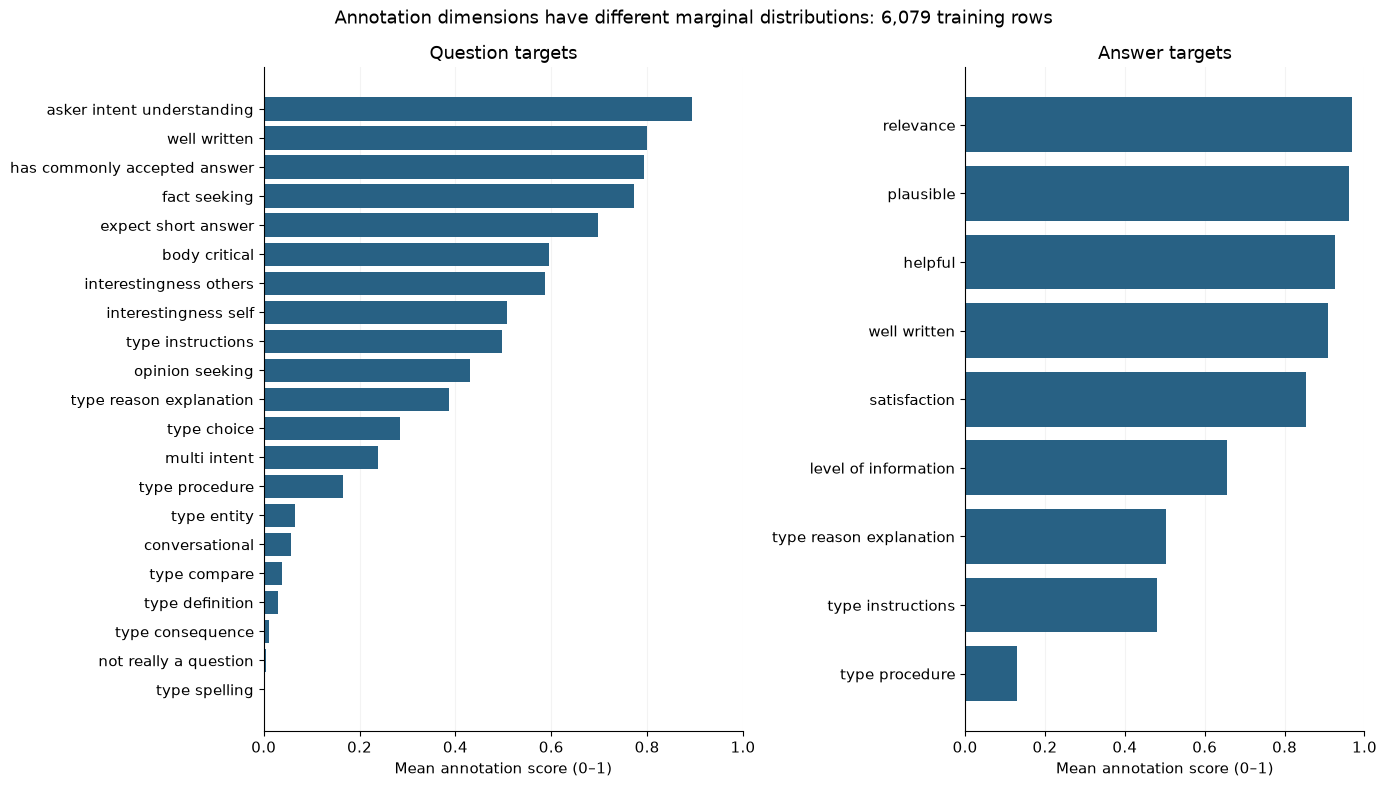

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 8), gridspec_kw={"width_ratios": [1.2, 1]})
for ax, columns, prefix, title in [
    (axes[0], QUESTION_TARGETS, "question_", "Question targets"),
    (axes[1], ANSWER_TARGETS, "answer_", "Answer targets"),
]:
    values = frame[list(columns)].mean().sort_values()
    labels = [name.removeprefix(prefix).replace("_", " ") for name in values.index]
    ax.barh(labels, values, color="#286184")
    ax.set(xlim=(0, 1), xlabel="Mean annotation score (0–1)", title=title)
    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)
fig.suptitle(f"Annotation dimensions have different marginal distributions: {len(frame):,} training rows")
fig.tight_layout()
plt.show()

The means describe annotation distributions, not model accuracy. A model could predict a frequent high score for every row yet fail to rank examples correctly. Spearman evaluates the ordering within each target before averaging the 30 correlations. Constant predictions contribute zero in the maintained metric; they are not dropped from the average.

## Repeated questions and validation

Different answers can share one question. An independent row split can expose a validation question during training. GroupKFold keeps these question groups together. The current recipe stratifies category domains while keeping exact question bodies together. A saved assignment file can freeze those IDs across library versions; a seed alone is not a cross-version identity contract.

{'training_rows': 4862, 'validation_rows': 1217, 'shared_question_groups': 0}


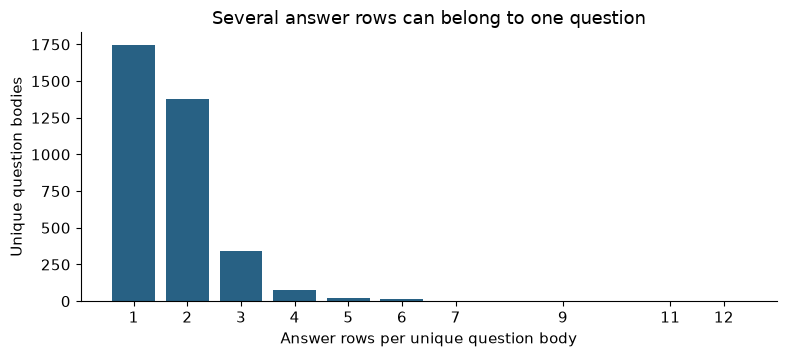

In [3]:
frozen_plan = plan_from_cv(CV_DIR) if (CV_DIR / "metrics.json").exists() else None
training_indices, validation_indices = split_fold(frame, fold=CONFIG["fold"], folds=CONFIG["folds"],
    protocol=CONFIG["split_protocol"], seed=CONFIG["split_seed"],
    frozen_plan=frozen_plan, input_sha256=sha256(DATA_DIR / "train.csv"))
groups = group_labels(frame)
assert not set(groups.iloc[training_indices]) & set(groups.iloc[validation_indices])
assert not set(frame.question_body.iloc[training_indices]) & set(frame.question_body.iloc[validation_indices])
print({"training_rows": len(training_indices), "validation_rows": len(validation_indices),
       "shared_question_groups": 0})
counts = frame.groupby("question_body", sort=False).size().value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3.7))
ax.bar(counts.index, counts.values, color="#286184")
ax.set(title="Several answer rows can belong to one question",
       xlabel="Answer rows per unique question body", ylabel="Unique question bodies")
ax.set_xticks(counts.index)
fig.tight_layout()
plt.show()

Each bar counts question bodies, while the model trains on question–answer rows. That distinction determines the leakage check. This is one grouped holdout, not five-fold out-of-fold evaluation. Further model selection against the same fold can still overfit that validation set.

## Shared transformer and padding-aware pooling

The encoder sees title/body and title/answer pairs separately, sharing its language-model weights. Mean pooling excludes padding positions. The prediction head receives both vectors and their difference, giving it information about each text and their relationship.

```text
title + body   ── shared DeBERTa ── masked mean ── question vector ──┐
title + answer ── shared DeBERTa ── masked mean ── answer vector ────┼─ head → 30 logits
                                                 difference ─────┘
```

[DeBERTa-v3-base](https://huggingface.co/microsoft/deberta-v3-base) replaces the historical BERT/distilRoBERTa presets. AdamW, warmup, cosine decay and gradient clipping use current PyTorch/Transformers APIs. The original code remains in `legacy/`; matching its score would establish a modern replacement's performance, not numerical equality with its TensorFlow graph.

In [4]:
print(json.dumps(CONFIG, indent=2))

{
  "name": "deberta-v3-base-question-group",
  "model": "microsoft/deberta-v3-base",
  "model_revision": "8ccc9b6f36199bec6961081d44eb72fb3f7353f3",
  "head_width": 768,
  "question_length": 384,
  "answer_length": 512,
  "fold": 0,
  "folds": 5,
  "head_epochs": 1,
  "epochs": 5,
  "batch_size": 4,
  "gradient_accumulation_steps": 2,
  "head_learning_rate": 0.001,
  "learning_rate": 2e-05,
  "weight_decay": 0.01,
  "warmup_fraction": 0.1,
  "max_gradient_norm": 1.0,
  "patience": 2,
  "seed": 42,
  "threads": 8,
  "mixed_precision": true,
  "device": "auto",
  "split_protocol": "category_stratified_group_v1",
  "split_seed": 42
}


Question and answer token budgets are explicit experimental choices. Gradient accumulation defines the effective batch size; the physical batch remains constrained by GPU memory. The best checkpoint maximizes grouped validation Spearman. Early stopping, token limits and the selected fold must remain visible when comparing results.

## Five-fold coverage and text-baseline stability

The split analyzer compares ordinary question-group folds with one predeclared category-stratified group plan: five folds and seed 42. There is no search for a favorable seed. Category is a domain proxy, not a direct multi-label stratifier, so the analyzer also checks every target's distribution, missingness and rare-group capacity.

The empirical CV model is **TF-IDF + Ridge**, with vocabulary and IDF fitted only on the training rows of each fold. It is a cheap stability diagnostic, not five-fold transformer training. Each row receives one out-of-fold prediction; repeated questions never cross a fold boundary.

,fold,validation_rows,mean_spearman_30_zero_fallback,defined_targets
0,0,1217,0.3272,30
1,1,1216,0.3315,30
2,2,1216,0.3269,30
3,3,1215,0.3253,30
4,4,1215,0.3228,30


{'pooled_oof_spearman': 0.3261137129346314, 'fold_mean': 0.3267266720331011, 'fold_standard_deviation': 0.0032046681016493967, 'model': 'train-only TF-IDF + Ridge; not transformer cross-validation'}


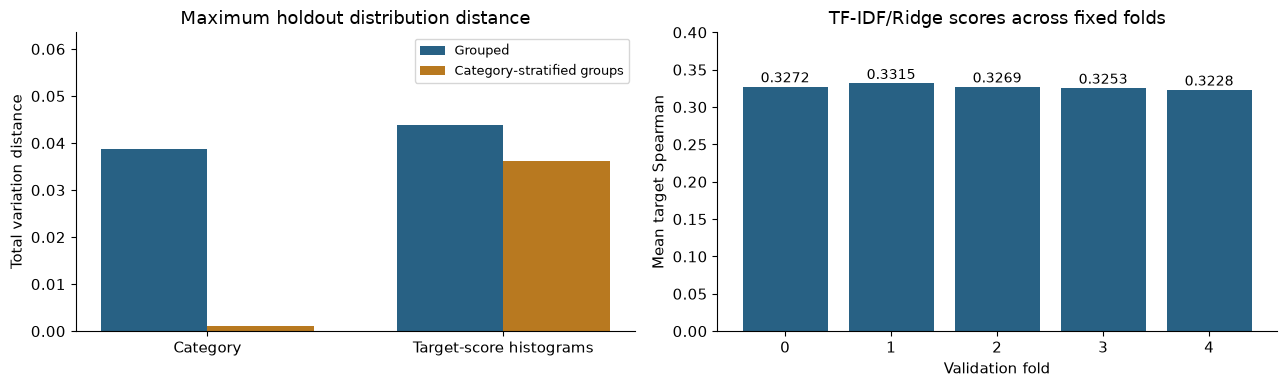

In [5]:
if (CV_DIR / "metrics.json").exists():
    cv = json.loads((CV_DIR / "metrics.json").read_text())
    analysis = json.loads((CV_DIR / "split-analysis.json").read_text())
    folds = pd.DataFrame(cv["fold_metrics"])
    display(folds[["fold", "validation_rows", "mean_spearman_30_zero_fallback", "defined_targets"]].round(4))
    print({"pooled_oof_spearman": cv["pooled_oof"]["mean_spearman_30_zero_fallback"],
           "fold_mean": cv["fold_mean_30_zero_fallback"],
           "fold_standard_deviation": cv["fold_std_30_zero_fallback"],
           "model": cv["model"]})
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    measures = ["max_category_total_variation", "max_target_distribution_total_variation"]
    for offset, protocol, label, color in [
        (-0.18, "group_v1", "Grouped", "#286184"),
        (0.18, "category_stratified_group_v1", "Category-stratified groups", "#b87920"),
    ]:
        values = [analysis["protocols"][protocol][name] for name in measures]
        axes[0].bar(np.arange(2) + offset, values, width=0.36, label=label, color=color)
    axes[0].set(xticks=[0, 1], xticklabels=["Category", "Target-score histograms"],
                title="Maximum holdout distribution distance", ylabel="Total variation distance")
    axes[0].set_ylim(0, max(patch.get_height() for patch in axes[0].patches) * 1.45)
    axes[0].legend(fontsize=9)
    axes[1].bar(folds.fold, folds.mean_spearman_30_zero_fallback, color="#286184")
    axes[1].set(xticks=folds.fold, ylim=(0, 0.4), xlabel="Validation fold",
                ylabel="Mean target Spearman", title="TF-IDF/Ridge scores across fixed folds")
    for row in folds.itertuples():
        axes[1].text(row.fold, row.mean_spearman_30_zero_fallback + 0.006,
                     f"{row.mean_spearman_30_zero_fallback:.4f}", ha="center", fontsize=10)
    fig.tight_layout()
    plt.show()
else:
    print("Run quest cv to create the full-data grouped baseline and split diagnostics.")

All five analyzed stratified folds have variation in all 30 targets. `question_type_spelling` has only eight question groups with nonmodal labels; checking this support matters because a locally regenerated legacy holdout missed that variation, while the actual saved hosted holdout retains it. Different library versions changed the regenerated membership; the benchmark uses its saved indices. In other datasets, fewer informative groups than folds can make full coverage impossible.

The reported fold SD describes dispersion for this model and this fixed split plan. It is not a confidence interval, proof of future stability, or a transformer CV estimate. Pooled OOF Spearman is recomputed over all held-out predictions together and need not equal the average of per-fold correlations.

## Recorded training and validation

A completed run contains its input and source hashes, resolved configuration, split roles, training history, per-target scores, tokenizer, checkpoint and predictions. Set `QUEST_BENCHMARK_DIR` to that retrieved run directory. Training is launched through `quest train` or the GPU notebook, so inspecting a finished experiment does not silently retrain it.

The recorded full transformer experiment uses the earlier, unstratified question-group holdout. Its exact recipe is retained in `configs/benchmark.json`; the current default uses the analyzed stratified protocol. Saved checkpoint indices remain authoritative for evaluating the recorded model.

{'logical_run_id': '15857179-b47b-45cf-991d-fad47363b2a8', 'grouped_holdout_spearman': 0.3778628686297344, 'training_rows': 4863, 'validation_rows': 1216, 'source': {'git_dirty': False, 'git_commit': '15f9429dff95cb106484da6d3a31ad017e1c354f', 'python_source_sha256': 'ad989899c113b0a0f07674ef8e60d2e126e532f029452d7a559aef28fefd0fd7', 'legacy_commit': 'ef4fb92c470e45c0a07b0ee0e474224d88d3d410'}}


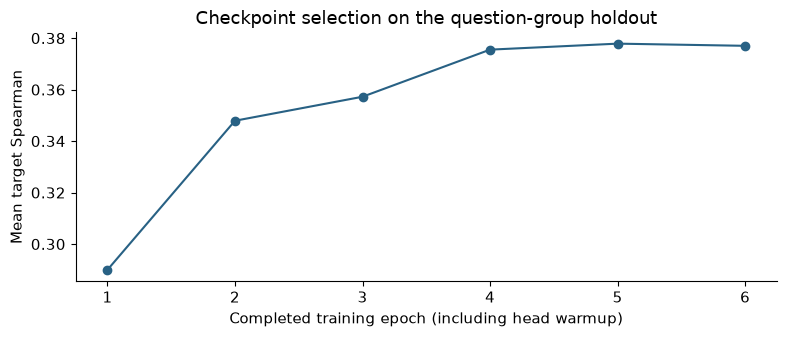

In [6]:
if (RUN_DIR / "manifest.json").exists():
    manifest = json.loads((RUN_DIR / "manifest.json").read_text())
    assert manifest["status"] == "completed", "Select a completed experiment"
    metrics = json.loads((RUN_DIR / "metrics.json").read_text())
    history = pd.read_json(RUN_DIR / "history.json")
    print({"logical_run_id": manifest["logical_run_id"],
           "grouped_holdout_spearman": metrics["mean_spearman"],
           "training_rows": manifest["train_rows"], "validation_rows": manifest["validation_rows"],
           "source": manifest["source"]})
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.plot(np.arange(1, len(history) + 1), history.validation_spearman, marker="o", color="#286184")
    ax.set(title="Checkpoint selection on the question-group holdout",
           xlabel="Completed training epoch (including head warmup)", ylabel="Mean target Spearman")
    ax.set_xticks(np.arange(1, len(history) + 1))
    fig.tight_layout()
    plt.show()
else:
    print("Set QUEST_BENCHMARK_DIR to the completed transformer run for result inspection.")

The held-out score measures ranking over this fold's rows. It should not be presented as the historical public leaderboard value. A useful next experiment changes one factor while retaining the split, then checks whether the finding survives additional folds.

## Recompute the saved ranking score

Spearman is Pearson correlation after converting each target and prediction column to ranks. This independent calculation joins saved holdout predictions to the original labels by `qa_id`, retains ties with average ranks, and averages all 30 target contributions. It checks the reported metric without running training again.

The actual hosted holdout has 30 defined targets. Do not substitute a fresh local split: it has different members despite the same input and grouping procedure.

In [7]:
if (RUN_DIR / "metrics.json").exists():
    heldout = pd.read_csv(RUN_DIR / "validation.csv").set_index("qa_id")
    actual = frame.set_index("qa_id").loc[heldout.index, list(TARGETS)]
    per_target = actual.rank().corrwith(heldout[list(TARGETS)].rank()).fillna(0)
    recomputed = float(per_target.mean())
    expected = json.loads((RUN_DIR / "metrics.json").read_text())["mean_spearman"]
    assert abs(recomputed - expected) < 1e-12
    print({"all_30_zero_fallback_spearman": recomputed,
           "defined_target_spearman": float(per_target[actual.nunique() > 1].mean()),
           "defined_targets": int((actual.nunique() > 1).sum()),
           "constant_holdout_targets": actual.columns[actual.nunique() == 1].tolist()})
else:
    print("Select the completed run to independently verify its held-out metric.")

{'all_30_zero_fallback_spearman': 0.37786286862973434, 'defined_target_spearman': 0.37786286862973434, 'defined_targets': 30, 'constant_holdout_targets': []}


## Checkpoint reuse and offline Kaggle inference

The run saves its encoder configuration, complete state and tokenizer, allowing inference without downloading the pretrained model again. `quest evaluate` checks the exact training-file hash and saved holdout indices. `quest predict` validates test IDs and writes all target columns in the official order.

QUEST is a notebook-only competition. The offline inference entry verifies run artifact hashes, predicts the competition-mounted test rows and writes `submission.csv`; the scoring request must identify its notebook version. Local public-test predictions alone do not establish a leaderboard score.

An optional MLflow import can connect a completed local or retrieved Kaggle run to an existing tracker. Training retains its evidence before any service connection. Shared infrastructure is managed separately.

See [architecture](../docs/architecture.md), [reproduction](../docs/reproduction.md) and [measured results](../docs/results.md).